# Visión por Computadora
## Clase 6 — Redes neuronales convolucionales (CNN)
### Unidad 2 · Redes convolucionales y modelos avanzados

**Laboratorio práctico (Google Colab).** La clase pasada entrenaste tu primer modelo, un **MLP**, y descubriste su límite: al **aplanar** la imagen perdía qué píxel estaba junto a cuál. Hoy construyes la red que resuelve ese problema: la **CNN**.

En vez de aplanar de entrada, la CNN **desliza filtros** sobre la imagen (la **convolución** de la Clase 3), pero **aprendiendo los filtros** sola. Vas a:

1. ver una convolución con un ejemplo diminuto de 3×3 antes de tocar una red,
2. construir una **CNN desde cero** (convolución, ReLU, pooling, dropout),
3. entrenarla sobre **FashionMNIST** y **compararla con el MLP**,
4. y, lo mejor, **abrir la red** y ver qué detecta cada capa con tu propia imagen.

**Cómo trabajar en Colab:** ejecuta cada celda con `Shift + Enter`. No necesitas instalar nada; Colab ya trae PyTorch. Antes de correr cada celda, intenta **predecir** qué va a pasar.

---

## Parte 0 — Preparar el entorno

Traemos las librerías. En Colab ya vienen instaladas, así que solo hay que importarlas (traerlas a esta sesión).

In [1]:
# ----------------------------------------------------------------------------
# Cada 'import' trae una caja de herramientas ya hecha.
# La palabra "as" le pone un apodo corto, para escribir menos después.
# ----------------------------------------------------------------------------
import numpy as np                     # NumPy: tablas de números (como en la Unidad 1)
import matplotlib.pyplot as plt        # Matplotlib: para dibujar imágenes y curvas
import torch                           # PyTorch: la librería de redes neuronales
import torch.nn as nn                  # nn: las piezas para armar redes (capas, activaciones)
import torchvision                     # torchvision: datasets e imágenes para PyTorch
from torchvision import transforms     # transforms: preparar las imágenes antes de usarlas

# Fijamos una "semilla" para que los números al azar salgan siempre iguales.
# Así, si repites el notebook, obtienes el mismo resultado (reproducibilidad).
torch.manual_seed(0)

# Si Colab tiene GPU activada, la usamos; si no, usamos el procesador normal (CPU).
# Para esta clase, la CPU basta. (Menú: Entorno de ejecución > Cambiar tipo > GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usaremos:", device)

Usaremos: cuda


---

## Parte 1 — Una convolución a mano, con una imagen de 3×3

Antes de cualquier red, veamos qué hace *una* convolución con un ejemplo diminuto. Regla del curso: **primero lo pequeño, después lo real.**

Vamos a crear una "imagen" de 5×5 con un borde vertical (una mitad oscura y otra clara) y a pasarle un **filtro** de 3×3 que detecta justo ese borde. Donde esté el borde, el resultado se encenderá.

In [2]:
# Una "imagen" de 5x5: la mitad izquierda en 0 (oscuro), la derecha en 1 (claro).
# El salto de 0 a 1 en el medio es un BORDE VERTICAL.
imagen = np.array([[0, 0, 1, 1, 1],
                   [0, 0, 1, 1, 1],
                   [0, 0, 1, 1, 1],
                   [0, 0, 1, 1, 1],
                   [0, 0, 1, 1, 1]], dtype=np.float32)

# Un filtro 3x3 que detecta bordes verticales: resta lo de la izquierda a lo de la derecha.
# Donde la izquierda y la derecha son distintas (un borde), da un número grande.
filtro = np.array([[-1, 0, 1],
                   [-1, 0, 1],
                   [-1, 0, 1]], dtype=np.float32)

print("Imagen 5x5:\n", imagen)
print("\nFiltro 3x3 (detector de borde vertical):\n", filtro)

Imagen 5x5:
 [[0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]]

Filtro 3x3 (detector de borde vertical):
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]


Mapa de activación (respuesta del filtro en cada posición):
 [[3. 3. 0.]
 [3. 3. 0.]
 [3. 3. 0.]]


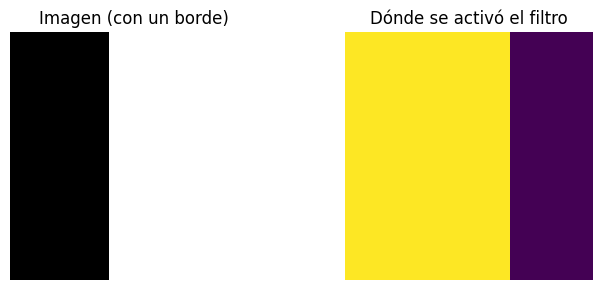

In [3]:
# Aplicamos el filtro A MANO, deslizándolo por la imagen (esto es una convolución).
# El filtro 3x3 solo cabe en las posiciones centrales, así que el resultado es 3x3.
resultado = np.zeros((3, 3), dtype=np.float32)   # aquí guardamos la respuesta en cada posición

for fila in range(3):                 # recorremos las 3 filas donde cabe el filtro
    for col in range(3):              # y las 3 columnas
        # tomamos el pedacito 3x3 de la imagen que está bajo el filtro ahora
        pedazo = imagen[fila:fila+3, col:col+3]
        # multiplicamos pedazo y filtro posición por posición, y sumamos todo:
        # ese número dice "cuánto calza" el filtro aquí.
        resultado[fila, col] = np.sum(pedazo * filtro)

print("Mapa de activación (respuesta del filtro en cada posición):\n", resultado)

# Lo dibujamos para verlo: la columna encendida es justo donde estaba el borde.
fig, (a, b) = plt.subplots(1, 2, figsize=(7, 3))
a.imshow(imagen, cmap="gray"); a.set_title("Imagen (con un borde)"); a.axis("off")
b.imshow(resultado, cmap="viridis"); b.set_title("Dónde se activó el filtro"); b.axis("off")
plt.tight_layout(); plt.show()

**Lo que acabas de ver es una convolución completa.** Deslizaste un filtro, y donde encontró su patrón (el borde), respondió fuerte. Una CNN hace exactamente esto, con una diferencia: **no eliges los números del filtro; la red los aprende sola.** Ahora pasemos a imágenes de verdad.

---

## Parte 2 — Los datos: FashionMNIST (fotos de ropa)

Usamos **FashionMNIST**: 70 000 fotos de ropa de 28×28 en gris, con 10 clases (camiseta, pantalón, zapatilla…). La clase pasada usamos dígitos; hoy pasamos a ropa, que tiene texturas más ricas y nos dejará ver mejor los mapas de activación.

La celda de abajo descarga el dataset y **muestra una grilla de ejemplos**, para que veas con qué estás trabajando.

In [4]:
# transform: la receta de preparación de cada imagen (aquí, solo pasarla a tensor 0..1)
transform = transforms.ToTensor()

# Descargamos FashionMNIST: una parte para ENTRENAR (60 000) y otra para EVALUAR (10 000).
# train=True trae las de entrenamiento; train=False, las de prueba (el "examen").
train_data = torchvision.datasets.FashionMNIST(root="./data", train=True,  download=True, transform=transform)
test_data  = torchvision.datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform)

# Los nombres de las 10 clases, en el mismo orden que usa el dataset (0 a 9).
CLASES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo",
          "sandalia", "camisa", "zapatilla", "bolso", "botín"]

# El DataLoader entrega los datos de a lotes de 64. shuffle=True baraja en cada época.
train_loader = torch.utils.data.DataLoader(train_data, batch_size=64, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_data,  batch_size=64, shuffle=False)

# Pedimos un lote y miramos su forma: [N, C, H, W] = [64 imágenes, 1 canal, 28 alto, 28 ancho].
X, y = next(iter(train_loader))
print("Forma de un lote:", tuple(X.shape))

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 163kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.28MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.5MB/s]

Forma de un lote: (64, 1, 28, 28)


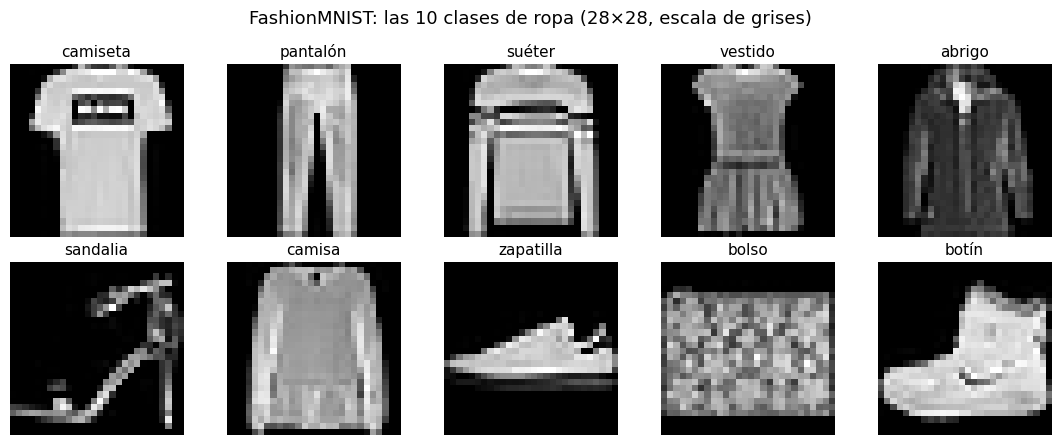

In [5]:
# Un vistazo al dataset: mostramos UNA prenda de cada una de las 10 clases.
# (Nunca se entrena sin mirar primero con qué datos trabajamos.)
fig, axs = plt.subplots(2, 5, figsize=(11, 4.5))
for clase_id, ax in enumerate(axs.flat):          # recorremos las 10 clases (0 a 9)
    # buscamos el primer ejemplo del dataset que sea de esta clase
    idx = next(i for i in range(len(train_data)) if train_data[i][1] == clase_id)
    imagen, etiqueta = train_data[idx]
    ax.imshow(imagen.squeeze(), cmap="gray")       # dibujamos la prenda
    ax.set_title(CLASES[etiqueta], fontsize=11)    # su nombre encima
    ax.axis("off")
plt.suptitle("FashionMNIST: las 10 clases de ropa (28×28, escala de grises)", fontsize=13)
plt.tight_layout(); plt.show()

---

## Parte 3 — La CNN, capa por capa

Aquí está el corazón de la clase. Compárala con el MLP de la clase pasada:

- El MLP hacía `Flatten` **al principio** y perdía el espacio.
- La CNN primero **mira** con `Conv2d` + `MaxPool2d` (el bloque `features`), y **recién al final** aplana para decidir (el bloque `classifier`).

Lee los comentarios de cada línea: dicen qué hace y qué forma deja.

In [6]:
class CNN(nn.Module):                     # definimos nuestra red; hereda de nn.Module
    def __init__(self):                   # aquí se declaran las piezas de la red
        super().__init__()                # arranca la maquinaria interna de PyTorch

        # --- BLOQUE QUE MIRA: extrae patrones respetando el espacio ---
        self.features = nn.Sequential(    # Sequential = aplica estas capas en orden
            # Conv2d(canales_entran, filtros, tamaño_filtro, padding)
            nn.Conv2d(1, 16, 3, padding=1),  # entra 1 canal (gris), salen 16 mapas; filtro 3x3
            nn.ReLU(),                       # activación: deja pasar lo positivo, apaga lo negativo
            nn.MaxPool2d(2),                 # pooling 2x2: resume y baja el tamaño de 28 a 14
            nn.Conv2d(16, 32, 3, padding=1), # entran 16 mapas, salen 32; más patrones
            nn.ReLU(),                       # otra activación
            nn.MaxPool2d(2),                 # otro pooling: baja de 14 a 7
        )

        # --- BLOQUE QUE DECIDE: recién ahora aplana y clasifica ---
        self.classifier = nn.Sequential(
            nn.Flatten(),                    # aplana: de 32 mapas de 7x7 a una fila de 32*7*7
            nn.Dropout(0.25),                # apaga 1 de cada 4 neuronas (evita memorizar)
            nn.Linear(32*7*7, 10),           # capa final: de 1568 números a 10 (una por clase)
        )

    def forward(self, x):                 # cómo fluye una imagen por la red
        x = self.features(x)              # 1) primero mira (convoluciones y pooling)
        return self.classifier(x)         # 2) luego decide (aplana y clasifica)

# Creamos la red y la mandamos al dispositivo (GPU o CPU).
model = CNN().to(device)
print(model)

# Contamos los parámetros (los números que la red ajustará). Compara con los 109 386 del MLP.
n_params = sum(p.numel() for p in model.parameters())
print(f"\nParámetros entrenables: {n_params:,}")

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=1568, out_features=10, bias=True)
  )
)

Parámetros entrenables: 20,490


**Fíjate en el número de parámetros: unos 20 500, cinco veces menos que los 109 386 del MLP.** Aunque la CNN es más potente, es más chica, porque **reutiliza el mismo filtro por toda la imagen** en vez de aprender un peso por píxel.

---

---

## Parte 3b — El MLP, nuestro punto de comparación

Antes de entrenar la CNN, armamos el **MLP** —la red de la clase pasada, la que aplana— pero esta vez **sobre la ropa**, para compararlos en igualdad de condiciones. Las dos redes verán exactamente las mismas imágenes.

El MLP aplana la imagen de entrada (pierde el espacio) y la pasa por dos capas densas.

In [7]:
class MLP(nn.Module):                      # la red de la clase pasada
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Flatten(),                  # aplana: 28x28 -> fila de 784 (pierde el espacio)
            nn.Linear(784, 128), nn.ReLU(),# capa densa 784 -> 128
            nn.Linear(128, 64),  nn.ReLU(),# capa densa 128 -> 64
            nn.Linear(64, 10),             # capa final -> 10 clases
        )
    def forward(self, x):
        return self.red(x)

mlp = MLP().to(device)
n_mlp = sum(p.numel() for p in mlp.parameters())
print(f"Parámetros del MLP: {n_mlp:,}")   # ~109 386, muchos más que la CNN

Parámetros del MLP: 109,386


La función de abajo entrena **cualquier** red (MLP o CNN) y devuelve su historial. La usaremos para las dos, así el entrenamiento es idéntico y la comparación es justa.

In [8]:
def entrenar(red, epocas=5):
    """Entrena una red sobre FashionMNIST y devuelve su exactitud de prueba por época."""
    criterio = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(red.parameters(), lr=0.001)
    hist = {"test_acc": [], "train_acc": [], "test_loss": [], "train_loss": []}

    def medir(loader):
        red.eval(); perd, ac, tot = 0.0, 0, 0
        with torch.no_grad():
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                s = red(X); perd += criterio(s, y).item()*X.size(0)
                ac += (s.argmax(1) == y).sum().item(); tot += X.size(0)
        return perd/tot, ac/tot

    for ep in range(1, epocas+1):
        red.train()
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            opt.zero_grad(); perdida = criterio(red(X), y)
            perdida.backward(); opt.step()
        trl, tra = medir(train_loader); tel, tea = medir(test_loader)
        hist["train_acc"].append(tra); hist["test_acc"].append(tea)
        hist["train_loss"].append(trl); hist["test_loss"].append(tel)
        print(f"  época {ep}/{epocas} | prueba: {tea*100:5.2f}%")
    return hist

print("Entrenando el MLP sobre ropa (tarda ~1 min)...")
hist_mlp = entrenar(mlp, epocas=5)
acc_mlp = hist_mlp["test_acc"][-1]
print(f"\nMLP sobre ropa: {acc_mlp*100:.2f}% de aciertos en prueba")

Entrenando el MLP sobre ropa (tarda ~1 min)...
  época 1/5 | prueba: 84.34%
  época 2/5 | prueba: 85.07%
  época 3/5 | prueba: 86.26%
  época 4/5 | prueba: 86.58%
  época 5/5 | prueba: 86.92%

MLP sobre ropa: 86.92% de aciertos en prueba


## Parte 4 — Pérdida y optimizador

Igual que la clase pasada: una **pérdida** que mide el error y un **optimizador** que la baja. Usamos `Adam`, una variante que ajusta el tamaño del paso sola y suele converger rápido.

In [9]:
criterion = nn.CrossEntropyLoss()                          # la pérdida: mide cuánto se equivoca
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)  # el optimizador: baja la pérdida
# lr = 0.001 es el tamaño del paso. Adam suele andar bien con ese valor.

---

## Parte 5 — El loop de entrenamiento

El **mismo motor de cinco pasos** de la clase pasada. No cambia ni una línea respecto al MLP: cambió la red, no el loop. Tarda uno o dos minutos.

In [10]:
def evaluar(loader):
    """Recorre un loader y devuelve (pérdida promedio, exactitud). No entrena."""
    model.eval()                                 # modo evaluación (apaga el dropout)
    perdida_total, aciertos, total = 0.0, 0, 0
    with torch.no_grad():                        # sin gradientes: va más rápido
        for X, y in loader:
            X, y = X.to(device), y.to(device)    # datos al mismo dispositivo que la red
            salida = model(X)                    # la red predice
            perdida = criterion(salida, y)       # cuánto se equivocó
            perdida_total += perdida.item() * X.size(0)
            aciertos += (salida.argmax(1) == y).sum().item()   # cuántos acertó
            total += X.size(0)
    return perdida_total / total, aciertos / total

In [11]:
# Entrenamos la CNN con la MISMA función, para que la comparación sea justa.
print("Entrenando la CNN sobre ropa (tarda ~1-2 min)...")
historial = entrenar(model, epocas=5)
acc_cnn = historial["test_acc"][-1]
print(f"\nCNN sobre ropa: {acc_cnn*100:.2f}% de aciertos en prueba")

Entrenando la CNN sobre ropa (tarda ~1-2 min)...
  época 1/5 | prueba: 86.50%
  época 2/5 | prueba: 87.25%
  época 3/5 | prueba: 89.03%
  época 4/5 | prueba: 89.33%
  época 5/5 | prueba: 90.16%

CNN sobre ropa: 90.16% de aciertos en prueba


---

## Parte 6 — Las curvas: CNN contra MLP

Comparamos las dos redes **sobre las mismas fotos de ropa**. La pérdida de la CNN debe bajar, y su exactitud debe quedar por encima de la del MLP.

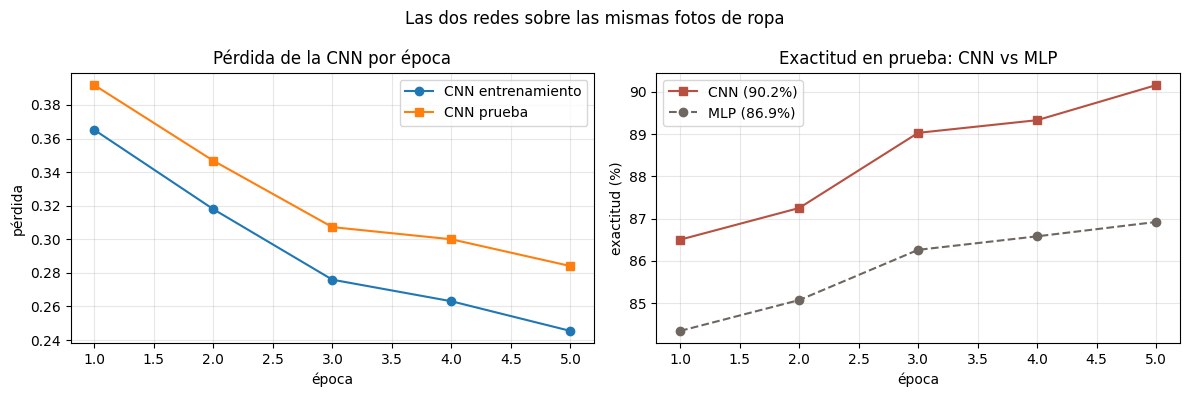

MLP sobre ropa: 86.92%   |   CNN sobre ropa: 90.16%
La CNN gana por 3.2 puntos, y con muchos menos parámetros.


In [12]:
epocas = range(1, len(historial["test_acc"]) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Izquierda: pérdida de la CNN, que debe BAJAR
ax1.plot(epocas, historial["train_loss"], "o-", label="CNN entrenamiento")
ax1.plot(epocas, historial["test_loss"], "s-", label="CNN prueba")
ax1.set_title("Pérdida de la CNN por época"); ax1.set_xlabel("época"); ax1.set_ylabel("pérdida")
ax1.legend(); ax1.grid(alpha=0.3)

# Derecha: exactitud de CNN vs MLP, ambas sobre ropa
ax2.plot(epocas, [a*100 for a in historial["test_acc"]], "s-", color="#B85042", label=f"CNN ({acc_cnn*100:.1f}%)")
ax2.plot(epocas, [a*100 for a in hist_mlp["test_acc"]], "o--", color="#6E6660", label=f"MLP ({acc_mlp*100:.1f}%)")
ax2.set_title("Exactitud en prueba: CNN vs MLP"); ax2.set_xlabel("época"); ax2.set_ylabel("exactitud (%)")
ax2.legend(); ax2.grid(alpha=0.3)

plt.suptitle("Las dos redes sobre las mismas fotos de ropa")
plt.tight_layout(); plt.show()

print(f"MLP sobre ropa: {acc_mlp*100:.2f}%   |   CNN sobre ropa: {acc_cnn*100:.2f}%")
print(f"La CNN gana por {(acc_cnn-acc_mlp)*100:.1f} puntos, y con muchos menos parámetros.")

---

## Parte 7 — Ver al modelo en acción

Predicciones sobre imágenes de prueba: en **verde** los aciertos, en **rojo** los errores. Los errores suelen ser prendas de verdad confusas (una camisa que parece suéter).

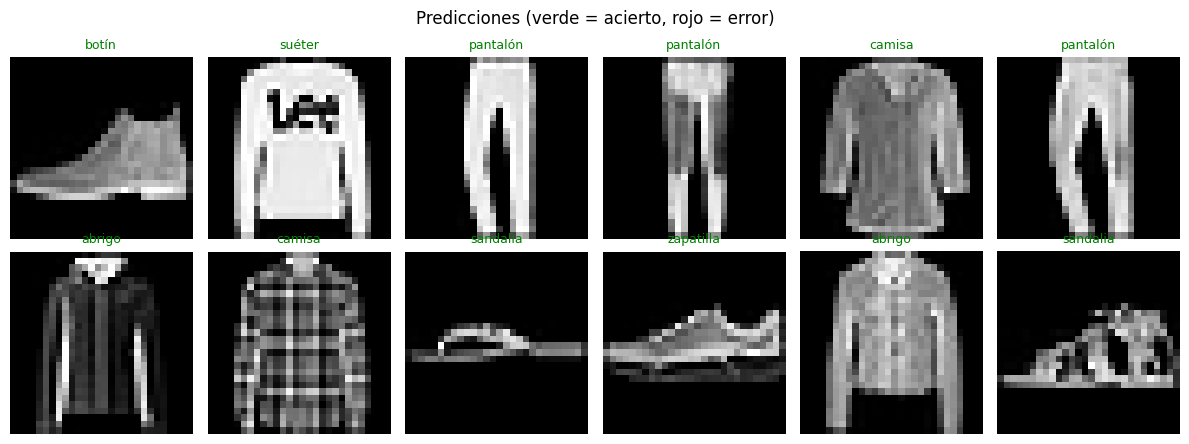

In [13]:
model.eval()                                     # modo evaluación
X, y = next(iter(test_loader))                   # un lote del examen
with torch.no_grad():
    pred = model(X.to(device)).argmax(1).cpu()   # la clase predicha para cada imagen

fig, axs = plt.subplots(2, 6, figsize=(12, 4.5))
for i, ax in enumerate(axs.flat):
    ax.imshow(X[i].squeeze(), cmap="gray")
    acierto = (pred[i] == y[i])                   # ¿acertó esta?
    color = "green" if acierto else "red"
    ax.set_title(CLASES[pred[i]], color=color, fontsize=9)
    ax.axis("off")
plt.suptitle("Predicciones (verde = acierto, rojo = error)")
plt.tight_layout(); plt.show()

---

## Parte 8 — Abrir la caja: los mapas de activación

El **momento central**. Sube tu propia imagen de una prenda y veremos: (A) qué predice la red, y (B) qué enciende cada capa por dentro.

**Celda A — sube tu imagen.** En Colab aparece un botón "Elegir archivos".

In [14]:
# ----------------------------------------------------------------------------
# SUBIDA DE ARCHIVO EN COLAB
# 'google.colab.files' solo existe en Colab; por eso se importa aquí.
# ----------------------------------------------------------------------------
from google.colab import files        # herramienta de Colab para subir archivos
import cv2                             # OpenCV: para leer y preparar la imagen

subidos = files.upload()              # aparece el botón "Elegir archivos"
imagen_bgr = None                     # aquí guardaremos tu foto

if len(subidos) == 0:                 # si no elegiste nada
    print("No subiste ninguna imagen. Vuelve a ejecutar esta celda y elige un archivo.")
else:
    primer_nombre = list(subidos.keys())[0]            # el nombre del archivo subido
    datos = subidos[primer_nombre]                     # sus bytes
    buffer = np.frombuffer(datos, dtype=np.uint8)      # bytes -> arreglo de números
    imagen_bgr = cv2.imdecode(buffer, cv2.IMREAD_COLOR)  # arreglo -> imagen (formato BGR)
    print("Imagen cargada:", primer_nombre)

Saving pantalon.png to pantalon.png
Imagen cargada: pantalon.png


**Celda B — preparamos tu imagen como FashionMNIST y la red la clasifica.**

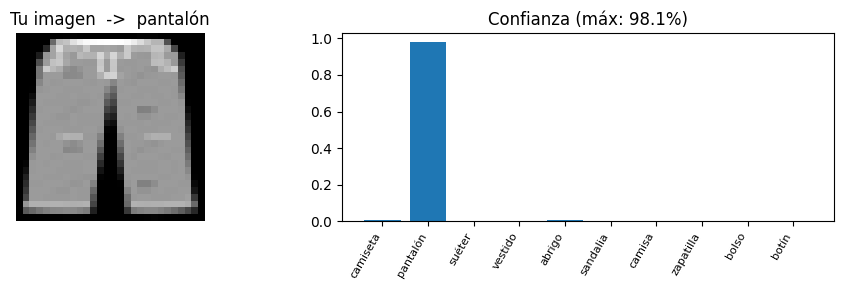

In [15]:
if imagen_bgr is None:
    print("Primero sube una imagen en la celda A.")
else:
    # 1) a gris y a 28x28 (el tamaño que la red espera)
    gris  = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)          # color -> gris
    chico = cv2.resize(gris, (28, 28), interpolation=cv2.INTER_AREA)  # a 28x28

    # 2) FashionMNIST es prenda CLARA sobre fondo OSCURO. Si tu foto es al revés, la invertimos.
    if chico.mean() > 127:                                        # si el promedio es claro...
        chico = 255 - chico                                       # ...invertimos

    # 3) a tensor con forma [1, 1, 28, 28] y escala 0..1
    x = torch.from_numpy(chico).float().unsqueeze(0).unsqueeze(0) / 255.0

    # 4) la red predice (probabilidad de cada clase)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(x.to(device)), dim=1)[0].cpu()  # 10 probabilidades
    pred = probs.argmax().item()                                    # la clase más probable

    # 5) mostramos tu imagen preparada y la confianza por clase
    fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3))
    a.imshow(chico, cmap="gray"); a.set_title(f"Tu imagen  ->  {CLASES[pred]}"); a.axis("off")
    b.bar(range(10), probs.numpy()); b.set_xticks(range(10))
    b.set_xticklabels(CLASES, rotation=60, ha="right", fontsize=8)
    b.set_title(f"Confianza (máx: {probs[pred]*100:.1f}%)")
    plt.tight_layout(); plt.show()

**Celda C — los mapas de activación.** Enganchamos la red para capturar lo que sale de cada capa convolucional y lo dibujamos. Córrela **después** de la celda B (usa la misma imagen `x`).

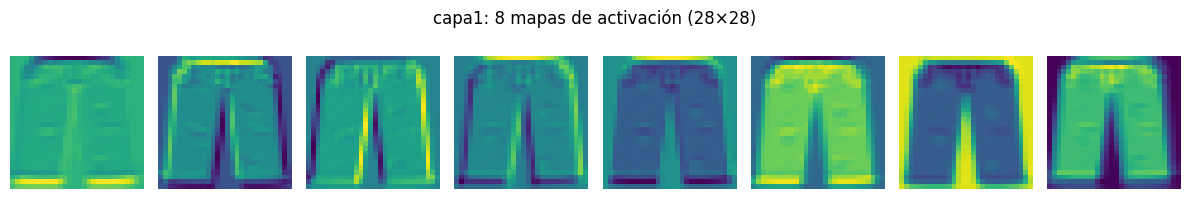

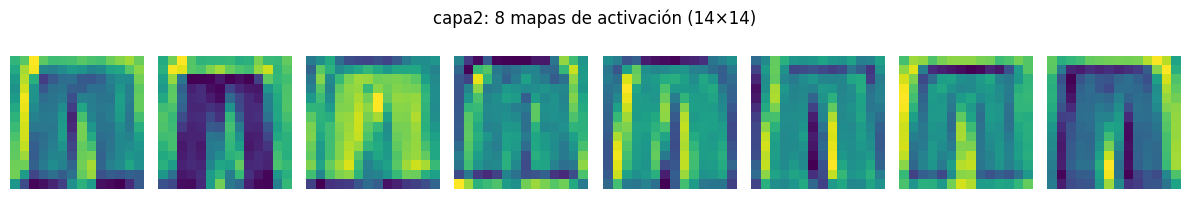

In [16]:
# Un "hook" es un espía: captura lo que produce una capa cuando la imagen pasa por ella.
activaciones = {}                                 # aquí guardaremos lo que vea cada capa

def guardar(nombre):
    def espia(modulo, entrada, salida):
        activaciones[nombre] = salida.detach().cpu()   # guardamos la salida de esa capa
    return espia

# features[0] es la 1ª convolución; features[3] es la 2ª (cuenta las capas del bloque features).
h1 = model.features[0].register_forward_hook(guardar("capa1"))
h2 = model.features[3].register_forward_hook(guardar("capa2"))

# Pasamos tu imagen por la red: eso dispara los espías y llena 'activaciones'.
model.eval()
with torch.no_grad():
    _ = model(x.to(device))

h1.remove(); h2.remove()                          # quitamos los espías (ya cumplieron)

def mostrar_mapas(nombre, cuantos=8):
    mapas = activaciones[nombre][0]               # [num_filtros, alto, ancho]
    cuantos = min(cuantos, mapas.shape[0])
    fig, axs = plt.subplots(1, cuantos, figsize=(1.5*cuantos, 2))
    for i in range(cuantos):
        axs[i].imshow(mapas[i], cmap="viridis")
        axs[i].axis("off")
    plt.suptitle(f"{nombre}: {cuantos} mapas de activación ({mapas.shape[1]}×{mapas.shape[2]})")
    plt.tight_layout(); plt.show()

mostrar_mapas("capa1")    # capa 1: bordes y contornos; aún reconoces tu prenda
mostrar_mapas("capa2")    # capa 2: más abstractos y pequeños; ya son patrones, no la foto

> **Léelo así:** en la **capa 1** cada mapa resalta bordes y contornos de tu prenda. En la **capa 2**, tras el pooling, los mapas son más pequeños y abstractos: la red dejó de mirar píxeles y empezó a mirar patrones. Esa abstracción creciente es justo lo que el MLP no podía construir.

---

## Parte 9 — TU TURNO: experimenta

Modifica la red o el entrenamiento y observa el efecto. Ideas:

- **Añade un tercer bloque** `Conv2d(32, 64, 3, padding=1)` + `ReLU` + `MaxPool2d(2)` y ajusta el `Linear` final (la salida quedaría en `64*3*3`).
- **Sube el `Dropout`** a `0.5` y mira si la brecha entre entrenamiento y prueba cambia.
- **Cambia los filtros** de la primera capa (8, 32…) y vuelve a mirar los mapas de activación.

Copia la clase `CNN`, cámbiale algo, crea el modelo y el optimizador de nuevo, y reentrena.

In [17]:
# TU TURNO — Escribe aquí tu variante.
# Pista: copia la clase CNN de la Parte 3, cambia una cosa, y vuelve a correr
# el optimizador (Parte 4) y el loop (Parte 5) con el nuevo modelo.

# class CNN2(nn.Module):
#     ...


### Pregunta escrita del laboratorio (para entregar)

**¿Por qué una CNN reconoce un objeto aunque esté desplazado en la imagen, y un MLP no?** Relaciónalo con dos ideas de hoy: el **mismo filtro** se aplica por toda la imagen, y el **pooling** da robustez a pequeños desplazamientos.

*(Escribe tu respuesta aquí, dos o tres líneas.)*

---

## Cierre

Construiste tu primera **CNN desde cero** y viste por qué supera al MLP: en vez de aplanar, **desliza filtros** que respetan la vecindad de los píxeles. Entrenaste con el **mismo loop** de la clase pasada, comparaste resultados y **abriste la red** para ver su jerarquía.

**Puente a la Clase 7.** La CNN es tan potente que puede **memorizar** en vez de aprender: el **sobreajuste**. Hoy pusimos un `Dropout` como primera defensa; la próxima clase abre toda la caja —validación, aumento de datos, matriz de confusión— para entrenar de forma honesta.